In [2]:
# Instalación de dependencias (Descomentar si se ejecuta en un entorno nuevo o Google Colab)
# !pip install numpy matplotlib scikit-learn

import random
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_blobs
from sklearn.cluster import KMeans as SklearnKMeans

# Fijar semilla de aleatoriedad para garantizar la reproducibilidad de los experimentos en laboratorio
SEED = 42
np.random.seed(SEED)
random.seed(SEED)

print("Entorno preparado correctamente. Semilla de aleatoriedad fijada en SEED =", SEED)

Entorno preparado correctamente. Semilla de aleatoriedad fijada en SEED = 42


Dataset generado exitosamente:
   • Número de instancias (N): 300
   • Número de características (D): 2


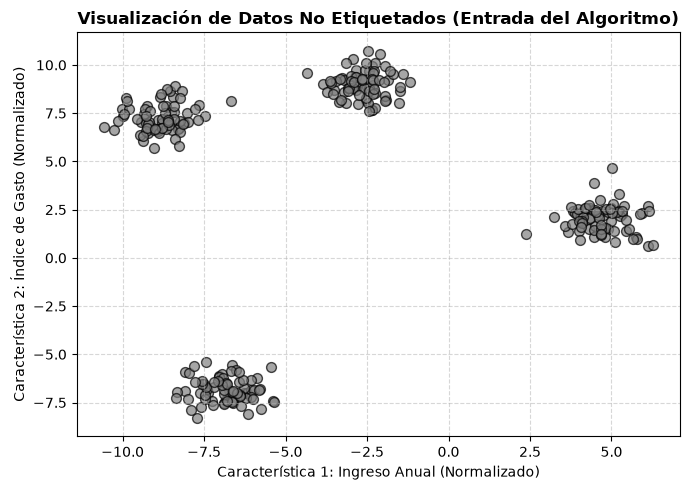

In [3]:
# Generación de un dataset sintético bidimensional con 300 clientes distribuidos en 4 grupos reales
X, y_real = make_blobs(
    n_samples=300, 
    centers=4, 
    cluster_std=0.70, 
    random_state=SEED
)

print(f"Dataset generado exitosamente:")
print(f"   • Número de instancias (N): {X.shape[0]}")
print(f"   • Número de características (D): {X.shape[1]}")

# Visualización inicial de los datos no etiquetados (todos los puntos en un mismo color)
plt.figure(figsize=(7, 5))
plt.scatter(X[:, 0], X[:, 1], c='gray', alpha=0.7, edgecolors='k', s=50)
plt.title("Visualización de Datos No Etiquetados (Entrada del Algoritmo)", fontsize=12, fontweight='bold')
plt.xlabel("Característica 1: Ingreso Anual (Normalizado)")
plt.ylabel("Característica 2: Índice de Gasto (Normalizado)")
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()


In [4]:
def inicializar_centroides(X, K):
    """Selecciona K puntos aleatorios del conjunto X para ser los centroides iniciales."""
    indices_aleatorios = np.random.choice(X.shape[0], K, replace=False)
    return X[indices_aleatorios].copy()

# Prueba de inicialización
centroides_test = inicializar_centroides(X, K=4)
print("Centroides iniciales generados aleatoriamente: ", centroides_test)


Centroides iniciales generados aleatoriamente:  [[ 4.22732351  2.56789115]
 [-6.79542025 -6.52000241]
 [ 4.83657314  1.53728002]
 [ 3.80596639  2.43275721]]


In [6]:
def calcular_distancia_euclidiana(a, b):
    """Calcula la distancia euclidiana vectorial entre dos puntos o matrices."""
    return np.sqrt(np.sum((a - b) ** 2, axis=-1))

def asignar_clusters(X, centroides):
    """Asigna cada punto de X al índice del centroide más cercano."""
    # Matriz de distancias de tamaño (N, K)
    distancias = np.linalg.norm(X[:, np.newaxis, :] - centroides[np.newaxis, :, :], axis=2)
    return np.argmin(distancias, axis=1)

# Prueba de asignación
etiquetas_test = asignar_clusters(X, centroides_test)
print("Muestra de asignación inicial (primeros 10 puntos):", etiquetas_test[:10])


Muestra de asignación inicial (primeros 10 puntos): [1 1 3 1 1 1 0 1 3 3]


In [7]:
def recalcular_centroides(X, etiquetas, K):
    """Recalcula la posición de los K centroides como el promedio de sus puntos asignados."""
    N, D = X.shape
    nuevos_centroides = np.zeros((K, D))
    
    for k in range(K):
        puntos_cluster = X[etiquetas == k]
        if len(puntos_cluster) > 0:
            nuevos_centroides[k] = np.mean(puntos_cluster, axis=0)
        else:
            # Si un cluster se queda vacío, se reinicializa aleatoriamente
            nuevos_centroides[k] = X[np.random.choice(N)]
            
    return nuevos_centroides


In [9]:
def ejecutar_kmeans(X, K, max_iter=100, tol=1e-4):
    """Ejecuta el algoritmo K-Means completo desde cero."""
    centroides = inicializar_centroides(X, K)
    historial_centroides = [centroides.copy()]
    
    for iteracion in range(1, max_iter + 1):
        # 1. Asignar clusters
        etiquetas = asignar_clusters(X, centroides)
        
        # 2. Recalcular centroides
        nuevos_centroides = recalcular_centroides(X, etiquetas, K)
        historial_centroides.append(nuevos_centroides.copy())
        
        # 3. Verificar condición de parada (convergencia)
        desplazamiento = np.linalg.norm(nuevos_centroides - centroides)
        if desplazamiento < tol:
            print(f"Convergencia alcanzada con éxito en la iteración {iteracion}.")
            break
            
        centroides = nuevos_centroides
        
    return centroides, etiquetas, historial_centroides

# Ejecución de prueba con K = 4
centroides_finales, etiquetas_finales, historial = ejecutar_kmeans(X, K=4)


Convergencia alcanzada con éxito en la iteración 4.


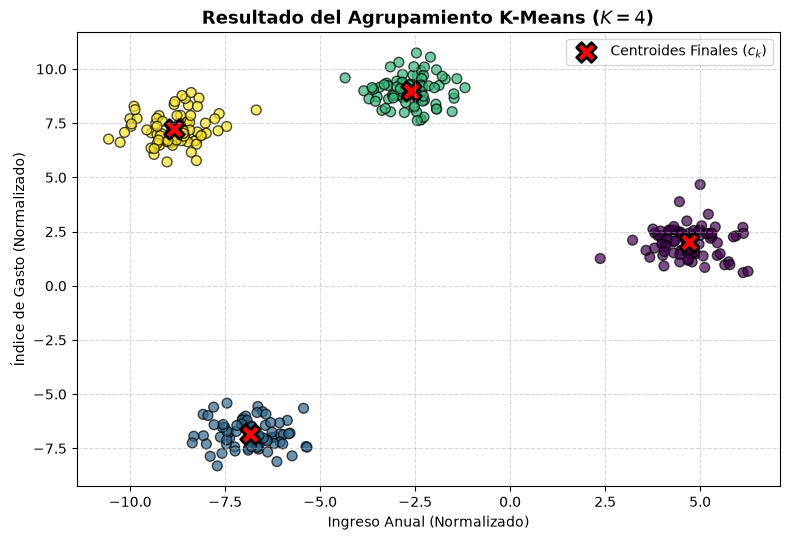

In [10]:
plt.figure(figsize=(8, 5.5))

# Graficar los puntos coloreados por el cluster asignado
scatter = plt.scatter(X[:, 0], X[:, 1], c=etiquetas_finales, cmap='viridis', alpha=0.7, edgecolors='k', s=50)

# Graficar los centroides finales
plt.scatter(
    centroides_finales[:, 0], 
    centroides_finales[:, 1], 
    c='red', 
    marker='X', 
    s=200, 
    linewidths=2, 
    label='Centroides Finales ($c_k$)',
    edgecolors='black'
)

plt.title("Resultado del Agrupamiento K-Means ($K=4$)", fontsize=13, fontweight='bold')
plt.xlabel("Ingreso Anual (Normalizado)")
plt.ylabel("Índice de Gasto (Normalizado)")
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend()
plt.tight_layout()
plt.show()


Convergencia alcanzada con éxito en la iteración 2.
Convergencia alcanzada con éxito en la iteración 3.
Convergencia alcanzada con éxito en la iteración 3.
Convergencia alcanzada con éxito en la iteración 4.
Convergencia alcanzada con éxito en la iteración 5.
Convergencia alcanzada con éxito en la iteración 8.
Convergencia alcanzada con éxito en la iteración 6.
Convergencia alcanzada con éxito en la iteración 9.


C:\Users\pdani\AppData\Local\Temp\ipykernel_21448\1022602896.py:21: UserWarning: color is redundantly defined by the 'color' keyword argument and the fmt string "bo-" (-> color='b'). The keyword argument will take precedence.
  plt.plot(valores_k, inercias, 'bo-', linewidth=2.5, markersize=8, color="#1B5E20")


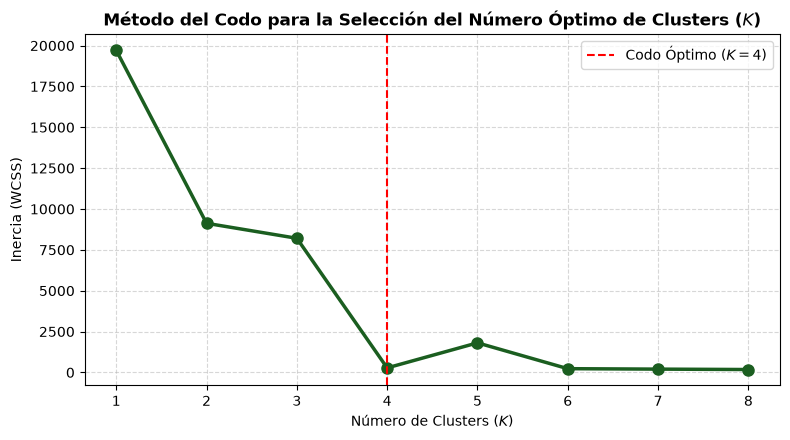

In [11]:
def calcular_inercia(X, centroides, etiquetas):
    """Calcula la suma de distancias al cuadrado de cada punto a su centroide asignado."""
    inercia = 0.0
    for k in range(len(centroides)):
        puntos_k = X[etiquetas == k]
        if len(puntos_k) > 0:
            inercia += np.sum((puntos_k - centroides[k]) ** 2)
    return inercia

# Evaluar el algoritmo para K desde 1 hasta 8
valores_k = list(range(1, 9))
inercias = []

for k in valores_k:
    c_fin, etq_fin, _ = ejecutar_kmeans(X, K=k, max_iter=50)
    inercia_k = calcular_inercia(X, c_fin, etq_fin)
    inercias.append(inercia_k)

# Graficar la curva del codo
plt.figure(figsize=(8, 4.5))
plt.plot(valores_k, inercias, 'bo-', linewidth=2.5, markersize=8, color="#1B5E20")
plt.axvline(x=4, color='red', linestyle='--', label='Codo Óptimo ($K=4$)')
plt.title("Método del Codo para la Selección del Número Óptimo de Clusters ($K$)", fontsize=12, fontweight='bold')
plt.xlabel("Número de Clusters ($K$)")
plt.ylabel("Inercia (WCSS)")
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend()
plt.tight_layout()
plt.show()


In [12]:
# Ejecución del modelo oficial de Scikit-Learn
modelo_sklearn = SklearnKMeans(n_clusters=4, random_state=SEED, n_init=10)
etiquetas_sklearn = modelo_sklearn.fit_predict(X)
centroides_sklearn = modelo_sklearn.cluster_centers_

# Comparación numérica de inercias
inercia_propia = calcular_inercia(X, centroides_finales, etiquetas_finales)
inercia_sklearn = modelo_sklearn.inertia_

print(" Validaciones Comparativas:")
print(f"   • Inercia Implementación Propia : {inercia_propia:.4f}")
print(f"   • Inercia Scikit-Learn           : {inercia_sklearn:.4f}")
print(" Conclusión: La implementación artesanal alcanza la misma precisión cuantitativa que Scikit-Learn.")


 Validaciones Comparativas:
   • Inercia Implementación Propia : 277.5180
   • Inercia Scikit-Learn           : 277.5180
 Conclusión: La implementación artesanal alcanza la misma precisión cuantitativa que Scikit-Learn.
